# KNOTS-06 — Empilements de cercles : Koebe–Andreev–Thurston et le Riemann mapping discret

**Série** : SymbolicAI / Lean — Knots Theory (compagnon géométrique)

KNOTS-04 descendait dans la géométrie hyperbolique d'un complémentaire de nœud ; ce carnet-ci prend l'autre porte de la même géométrie : les **empilements de cercles**. Le théorème de Koebe–Andreev–Thurston (KAT) dit qu'une triangulation d'un disque porte exactement un empilement de cercles tangents, unique à homothétie près — et le théorème de Rodin–Sullivan ajoute que quand le maillage se raffine, la carte d'empilement **converge vers la carte conforme**. La conformité devient un objet calculable par le packing.

Le pont est réciproque : le carnet [08-riemann-mapping](../Riemann200/08-riemann-mapping.ipynb) de la série Riemann 200 calcule sa carte conforme par Schwarz–Christoffel, côté continu. Ici, la même carte devient l'instrument de mesure : son inverse transporte le maillage dans le disque, et la déformation des cercles — mesurée puis raffinée — quantifie la conformité que le théorème de Rodin–Sullivan relie au discret.

Part of #20404 (pli 5) — épic sœur #20403.

## Navigation

**Navigation** : [<< KNOTS-05 — Dynamique des tresses](KNOTS-05-Dynamique-Tresses-Python.ipynb) | [Index](README.md) | [KNOTS-07 — Feuilletages et classe de Godbillon–Vey >>](KNOTS-07-Feuilletages-Godbillon-Vey-Python.ipynb) | [Série Lean](../README.md)

## Plan

1. **Le théorème KAT et le témoin hexagonal** — l'énoncé, puis la vérification sur la fleur hexagonale (le cas exact)
2. **La relaxation des rayons** — l'algorithme de Stephenson : bord imposé, trou percé, la même équation locale
3. **Le layout** — dessiner l'empilement : tangences exactes, univalence mesurée
4. **La carte de Schwarz–Christoffel** — son inverse par Newton, et l'excentricité des cercles transportés, à quatre niveaux de raffinement
5. **Le pont, côte à côte** — le domaine et son transport par l'inverse de la carte, dans le disque
6. **Le contre-témoin : l'anneau** — deux composantes de bord, un profil de rayons, et le certificat d'obstruction : le trou dépasse $2\pi$

## Prérequis

- Dépendances : voir [KNOTS-06-Empilements-Cercles-Python-requirements.txt](KNOTS-06-Empilements-Cercles-Python-requirements.txt) (matplotlib ; le reste est stdlib : `math`, `cmath`)
- Lecture recommandée : KNOTS-04 (géométrie hyperbolique) pour la parenté d'esprit ; aucun prérequis technique


In [1]:
import math
import cmath
from collections import defaultdict

import matplotlib
import matplotlib.pyplot as plt

# Versions mesurées sur le siège d'exécution (cf. SCRIPTS_NOTEBOOK_KNOTS_06 / body PR).
print("matplotlib {}".format(matplotlib.__version__))

matplotlib 3.11.1


## 1. Le théorème KAT et le témoin hexagonal

**Théorème (Koebe 1936 ; Andreev 1970 ; Thurston 1978).** Toute triangulation d'un disque est le **graphe de contact** d'un empilement de cercles tangents — et cet empilement est unique à homothétie près. La preuve de Thurston passe par la géométrie hyperbolique (le même monde que KNOTS-04) ; la donnée qui rend le théorème *calculable* est locale : dans un triangle de la triangulation, les trois rayons $(r_i, r_j, r_k)$ déterminent les **angles aux centres** par la seule loi des cosinus.

Pour trois cercles tangents deux à deux, les centres forment un triangle de côtés $r_i+r_j$, $r_j+r_k$, $r_k+r_i$. L'angle $\gamma_k$ de la fleur au sommet $k$ — l'angle au centre $k$ de ce triangle des centres — est donné par la loi des cosinus :

$$\cos\gamma_k = \frac{(r_k+r_i)^2 + (r_k+r_j)^2 - (r_i+r_j)^2}{2\,(r_k+r_i)(r_k+r_j)}.$$

La **fleur hexagonale** — un cercle central, six voisins tangents en cycle, tous de rayon 1 — est le cas exact : le triangle des centres est équilatéral, chaque angle vaut $\pi/3$, et la fleur referme $6 \times \pi/3 = 2\pi$ pile. C'est le témoin positif : la formule reproduit le fait vérifiable à la main. (L'angle de l'*interstice* curviligne entre les trois cercles est lui $\pi - \gamma_k$ — c'est l'autre somme, celle du domaine complémentaire, qui vaut $2\pi$ pour les trois sommets d'un même interstice ; les deux livres de comptes se tiennent, mais l'algorithme de packing compte en $\gamma_k$.)

In [2]:
def angle_au_centre(r_i, r_j, r_k):
    # Angle de la fleur au sommet k : angle au centre k du triangle des
    # centres de trois cercles (i, j, k) tangents deux a deux (loi des cosinus).
    # Forme stable de Collins-Stephenson (2003, eq. 4.2), algebriquement
    # equivalente a la loi des cosinus mais sans carre de grands rayons.
    # Angle au centre k du triangle de cercles (i, j, k) tangents.
    if r_i <= 0 or r_j <= 0 or r_k <= 0:
        raise ValueError("rayon non positif")
    # sin(gamma_k / 2) = sqrt(r_i r_j / ((r_k+r_i)(r_k+r_j)))
    u = math.sqrt(r_i / (r_k + r_i)) * math.sqrt(r_j / (r_k + r_j))
    return 2 * math.asin(max(-1.0, min(1.0, u)))

# Temoin : la fleur hexagonale, tous rayons egaux a 1.
angles = [angle_au_centre(1.0, 1.0, 1.0) for _ in range(6)]
somme = sum(angles)
print("angle au centre (r=1,1,1) = {:.6f} rad = {:.6f} * pi".format(angles[0], angles[0] / math.pi))
print("somme de la fleur (6 voisins) = {:.6f} rad = {:.6f} * 2pi".format(somme, somme / (2 * math.pi)))

angle au centre (r=1,1,1) = 1.047198 rad = 0.333333 * pi
somme de la fleur (6 voisins) = 6.283185 rad = 1.000000 * 2pi


**Lecture du résultat.** L'angle au centre vaut $0{,}333333\,\pi = \pi/3$ à la sixième décimale, et la fleur referme $1{,}000000 \times 2\pi$ : la formule coïncide avec la géométrie exacte de la fleur régulière. Toute la machinerie qui suit repose sur cette seule fonction — le théorème KAT dit qu'en résolvant les rayons pour que *chaque* fleur referme $2\pi$, les tangences s'organisent d'elles-mêmes.

## 2. La relaxation des rayons — l'algorithme de Stephenson

La relaxation repose sur une monotonie : la somme d'angles d'une fleur **décroît strictement** quand son propre rayon croît (voisins fixés). Le régime de travail est le **bord imposé** : chaque rayon intérieur est ajusté pour que sa fleur referme $2\pi$, et les rayons de bord restent à leur valeur imposée : $1$ par défaut, ou la valeur fournie dans `rayons_bord` pour les sommets listés (pattern hétérogène, comme le pourtour du trou à la section 6). La fleur d'un bord est ouverte — elle ne referme $2\pi$ que par la géométrie globale du layout, jamais par la contrainte locale. Le choix numérique est le **modèle de voisin uniforme** (UNM) de Collins–Stephenson (2003, §3.2-3.3) : on cherche d'abord le rayon commun $\hat r$ des pétales qui reproduit la somme d'angles actuelle, puis on ajuste le rayon central pour atteindre la cible dans ce modèle uniforme. Leur lemme 3.1 garantit que cette correction ne dépasse pas la cible, donc fait décroître l'erreur totale ; l'algorithme ne se réduit pas à une dichotomie locale générique.

Le maillage de travail est un **carré en base losange** — quatre coins exacts, degré 6 aux sommets intérieurs — que la section 5 transportera dans le disque. Ses coins sont placés aux images des pré-sommets $\pm 1, \pm i$ par la carte de Schwarz–Christoffel du disque, c'est-à-dire à $\pm A$ et $\pm iA$ où

$$A = \int_0^1 \frac{dt}{\sqrt{1 - t^4}} = \frac{\Gamma(1/4)^2}{4\sqrt{2\pi}} \approx 1{,}311029$$

est la constante lemniscatique — la carte SC est construite et démontrée à la section 4.

In [3]:
# Constante lemniscatique : demi-diagonale du carre image de la carte SC du disque.
A_LEMNISCATE = math.gamma(0.25) ** 2 / (4 * math.sqrt(2 * math.pi))
print("A = Gamma(1/4)^2 / (4 sqrt(2 pi)) = {:.6f}".format(A_LEMNISCATE))


def maillage_losange(n, demi_diag, exclure=frozenset()):
    # Carre en base losange : n x n cellules, chaque cellule coupee en 2 triangles.
    # Les 4 sommets de coin existent exactement ; exclure retire des sommets
    # (pour le contre-temoin anneau). Renvoie positions, faces, bord, coins, idx.
    e1 = (demi_diag / n) * (1 + 1j)
    e2 = (demi_diag / n) * (-1 + 1j)
    positions = []
    idx = {}
    for i in range(n + 1):
        for j in range(n + 1):
            if (i, j) in exclure:
                continue
            idx[(i, j)] = len(positions)
            positions.append((i - n / 2) * e1 + (j - n / 2) * e2)
    faces = []
    for i in range(n):
        for j in range(n):
            if any((a, b) not in idx for a, b in ((i, j), (i + 1, j), (i + 1, j + 1), (i, j + 1))):
                continue
            a = idx[(i, j)]
            b = idx[(i + 1, j)]
            c = idx[(i + 1, j + 1)]
            d = idx[(i, j + 1)]
            faces.append((a, b, c))
            faces.append((a, c, d))
    aretes = defaultdict(int)
    for f in faces:
        for u, v in ((f[0], f[1]), (f[1], f[2]), (f[2], f[0])):
            aretes[frozenset((u, v))] += 1
    bord = set()
    for e, nb in aretes.items():
        if nb == 1:
            bord.update(e)
    coins = {"droite": idx[(n, 0)], "haut": idx[(n, n)], "gauche": idx[(0, n)], "bas": idx[(0, 0)]}
    aretes_mesh = set(aretes)
    return positions, faces, bord, coins, idx, aretes_mesh


def fleur(faces):
    # faces incidentes par sommet + voisins dans l'ordre cyclique.
    # Sommet interieur : fleur fermee ; sommet de bord : chaine ouverte,
    # etendue dans les DEUX sens depuis une premiere face incidente.
    faces_sommet = defaultdict(list)
    arete_faces = defaultdict(list)
    for f in faces:
        for s in f:
            faces_sommet[s].append(f)
        for u, v in ((f[0], f[1]), (f[1], f[2]), (f[2], f[0])):
            arete_faces[frozenset((u, v))].append(f)

    def autre_voisin(face, s, exclu):
        j = face.index(s)
        w = face[(j + 1) % 3]
        return w if w != exclu else face[(j + 2) % 3]

    voisins = {}
    for s, fs in faces_sommet.items():
        f0 = fs[0]
        i0 = f0.index(s)
        u, v = f0[(i0 + 1) % 3], f0[(i0 + 2) % 3]
        ring = [u, v]
        cur, ferme = f0, False
        while True:
            nxt = [g for g in arete_faces[frozenset((s, ring[-1]))] if g is not cur]
            if not nxt:
                break
            cur = nxt[0]
            w = autre_voisin(cur, s, ring[-1])
            if w == ring[0]:
                ferme = True
                break
            ring.append(w)
        if not ferme:
            cur = f0
            while True:
                nxt = [g for g in arete_faces[frozenset((s, ring[0]))] if g is not cur]
                if not nxt:
                    break
                cur = nxt[0]
                ring.insert(0, autre_voisin(cur, s, ring[0]))
        voisins[s] = ring
    return faces_sommet, voisins


def somme_fleur(s, rayons, faces_sommet):
    # Somme des angles curvilignes au sommet s sur toutes ses faces incidentes.
    tot = 0.0
    for f in faces_sommet[s]:
        i, j, k = f
        if i == s:
            u, v = j, k
        elif j == s:
            u, v = k, i
        else:
            u, v = i, j
        tot += angle_au_centre(rayons[u], rayons[v], rayons[s])
    return tot


def relaxer(positions, faces, bord, tol=1e-10, balayages=300, verboux=False, rayons_bord=None):
    # Collins-Stephenson 2003, section 3.2-3.3 : UNM (Uniform Neighbor Model).
    # On remplace les petales par des cercles de meme rayon r_hat reproduisant
    # la somme actuelle, puis on ajuste le centre dans ce modele uniforme.
    # Lemme 3.1 : la correction ne depasse pas la cible et l'erreur totale
    # decroit. Les fleurs referment toutes 2 pi ; un sommet de bord liste
    # dans rayons_bord reste fige a la valeur imposee.
    faces_sommet, voisins = fleur(faces)
    rayons = [1.0] * len(positions)
    if rayons_bord:
        for s, r in rayons_bord.items():
            rayons[s] = r
    residus = []
    for b in range(balayages):
        res = 0.0
        for s in range(len(positions)):
            if s in bord:
                continue
            but = 2 * math.pi
            s0 = somme_fleur(s, rayons, faces_sommet)
            res = max(res, abs(s0 - but))
            if abs(s0 - but) < tol:
                continue
            # UNM : r_hat est le rayon commun de k petales donnant s0
            # avec le centre actuel r. En r_hat la somme k*angle est
            # strictement croissante, de 0 vers k*pi (en r centre elle
            # est decroissante) : on encadre par doublements puis dichotomie.
            ring = voisins[s]
            k = len(ring)
            lo, hi = 1e-14, max(1e-14, max(rayons[t] for t in ring))
            # Garde de saturation : en flottant la somme plafonne a k*pi ;
            # un s0 arrondi au-dessus ne serait sinon jamais depasse.
            cible = min(s0, k * math.pi * (1.0 - 1e-12))
            while k * angle_au_centre(hi, hi, rayons[s]) < cible:
                hi *= 2
            for _ in range(52):
                mid = (lo + hi) / 2
                if k * angle_au_centre(mid, mid, rayons[s]) < cible:
                    lo = mid
                else:
                    hi = mid
            r_hat = (lo + hi) / 2
            # A voisinage uniforme, chaque angle vaut
            # 2 asin(r_hat / (r_hat + r)) : la cible par petale est but/k,
            # donc sin(but/(2k)) = r_hat / (r_hat + r), d'ou r.
            sin_cible = max(0.0, min(1.0, math.sin(but / (2 * k))))
            rayons[s] = r_hat * (1.0 / sin_cible - 1.0)
        residus.append(res)
        if verboux and (b < 5 or b % 10 == 0 or res < tol):
            print("  balayage {:3d} : residu max des sommes de fleurs = {:.3e}".format(b + 1, res))
        if res < tol:
            break
    return rayons, residus

A = Gamma(1/4)^2 / (4 sqrt(2 pi)) = 1.311029


In [4]:
# Demonstration (a) : le carre plein, plus petit niveau du pont (n = 6).
# Tous les sommets interieurs y sont de degre 6 : la solution KAT est le reseau
# hexagonal, rayons tous egaux -- la relaxation le certifie en un seul balayage.
positions6, faces6, bord6, coins6, idx6, aretes6 = maillage_losange(6, A_LEMNISCATE)
print("carre plein n=6 : {} sommets, {} faces, {} de bord".format(len(positions6), len(faces6), len(bord6)))
rayons6, residus6 = relaxer(positions6, faces6, bord6, tol=1e-10)
print("  convergence en {} balayage(s), residu final {:.2e}, rayons tous a {:.4f}".format(
    len(residus6), residus6[-1], max(rayons6)))

# Demonstration (b) : le meme carre perce d'un trou (bloc 3x3 central retire),
# avec un pattern de bord heterogene : les cercles du pourtour du trou sont
# fixes a 0.1. Les fleurs interieures proches du trou doivent s'adapter --
# la relaxation devient iterative et les rayons cessent d'etre uniformes.
TROU = {(i, j) for i in range(4, 7) for j in range(4, 7)}
pa, fa, ba, ca, ixa, ara = maillage_losange(10, A_LEMNISCATE, TROU)
bord_ext_a = {s for (i, j), s in ixa.items() if i in (0, 10) or j in (0, 10)}
bord_trou_a = ba - bord_ext_a
print("maillage perce n=10 : {} sommets, dont {} au bord du trou (rayon fixe 0.1)".format(len(pa), len(bord_trou_a)))
ra, resa = relaxer(pa, fa, ba, tol=1e-10, verboux=True, rayons_bord={s: 0.1 for s in bord_trou_a})
print("  convergence en {} balayages, rayons de [{:.4f} a {:.4f}]".format(len(resa), min(ra), max(ra)))

# La comparaison (a)/(b) est la charge utile du KAT : la MEME equation locale,
# deux jeux de conditions de bord, deux geometries globales differentes.

carre plein n=6 : 49 sommets, 72 faces, 24 de bord
  convergence en 1 balayage(s), residu final 1.78e-15, rayons tous a 1.0000
maillage perce n=10 : 112 sommets, dont 16 au bord du trou (rayon fixe 0.1)
  balayage   1 : residu max des sommes de fleurs = 2.417e+00
  balayage   2 : residu max des sommes de fleurs = 1.215e+00
  balayage   3 : residu max des sommes de fleurs = 6.694e-01
  balayage   4 : residu max des sommes de fleurs = 3.898e-01
  balayage   5 : residu max des sommes de fleurs = 2.276e-01
  balayage  11 : residu max des sommes de fleurs = 7.893e-03
  balayage  21 : residu max des sommes de fleurs = 2.861e-05
  balayage  31 : residu max des sommes de fleurs = 8.920e-08
  balayage  41 : residu max des sommes de fleurs = 2.701e-10
  balayage  44 : residu max des sommes de fleurs = 9.805e-11
  convergence en 44 balayages, rayons de [0.1000 a 1.0000]


**Lecture du résultat.** Deux régimes, une même équation. Sur le carré plein, tous les intérieurs sont de degré 6 et la solution KAT est le réseau hexagonal — la relaxation le certifie en un balayage, résidu au niveau machine : c'est une vérification numérique du théorème, pas une trivialité du code. Dès que le pattern de bord devient hétérogène (trou percé, cercles du pourtour fixés petits), les fleurs voisines doivent s'adapter, l'adaptation se propage de proche en proche, et la relaxation devient itérative — les rayons couvrent toute la plage entre 0,1 et 1. C'est la leçon du KAT : la solution ne dépend que de la combinatoire **et** des conditions de bord ; la géométrie globale, elle, n'est jamais imposée.

## 3. Le layout — dessiner l'empilement

Les rayons résolus, on place les centres : une première face est posée avec ses tangences exactes, puis chaque sommet restant est placé à l'**intersection de deux cercles de tangence** (celles de ses deux voisins déjà placés consécutifs), du côté validé par tous ses autres voisins déjà placés — le cercle nouveau ne chevauche personne. À la fin, on mesure ce que le théorème promet : chaque arête du maillage relie des centres à distance $r_u + r_v$ exactement (tangence), et deux cercles non voisins ne se chevauchent pas (univalence).

In [5]:
def _intersection(cA, dA, cB, dB):
    # Les deux points a distance dA de cA et dB de cB.
    d = abs(cB - cA)
    x = (dA * dA - dB * dB + d * d) / (2 * d)
    h = math.sqrt(max(0.0, dA * dA - x * x))
    u = (cB - cA) / d
    return cA + x * u + h * 1j * u, cA + x * u - h * 1j * u


def placer(positions, faces, rayons, faces_sommet, voisins, aretes_mesh, tol=1e-6):
    # Pose une premiere face, puis placement glouton valide par les voisins deja places.
    pos_c = {}
    a, b, c = faces[0]
    pos_c[a] = 0j
    pos_c[b] = complex(rayons[a] + rayons[b], 0.0)
    p1, p2 = _intersection(pos_c[a], rayons[a] + rayons[c], pos_c[b], rayons[b] + rayons[c])
    pos_c[c] = p1
    reste = set(range(len(positions))) - set(pos_c)
    progres = True
    while reste and progres:
        progres = False
        for v in sorted(reste):
            ring = voisins[v]
            ferme = len(ring) == len(faces_sommet[v])  # sommet interieur : fleur complete
            paires = [(ring[k], ring[k + 1]) for k in range(len(ring) - 1)]
            if ferme:
                paires.append((ring[-1], ring[0]))
            choix = None
            for u, w in paires:
                if u not in pos_c or w not in pos_c:
                    continue
                c1, c2 = _intersection(pos_c[u], rayons[u] + rayons[v],
                                       pos_c[w], rayons[w] + rayons[v])
                for cand in (c1, c2):
                    ok = True
                    for t in ring:
                        if t in (u, w) or t not in pos_c:
                            continue
                        if abs(cand - pos_c[t]) < rayons[v] + rayons[t] - tol:
                            ok = False
                            break
                    if ok:
                        choix = cand
                        break
                if choix is not None:
                    break
            if choix is not None:
                pos_c[v] = choix
                reste.discard(v)
                progres = True
    return pos_c, reste


def verifier(positions, rayons, pos_c, aretes_mesh):
    # Tangence sur les aretes ; univalence sur les paires non voisines.
    tangence = 0.0
    for e in aretes_mesh:
        u, w = tuple(e)
        tangence = max(tangence, abs(abs(pos_c[u] - pos_c[w]) - (rayons[u] + rayons[w])))
    univalence = float("inf")
    sommets = sorted(pos_c)
    for k, u in enumerate(sommets):
        for w in sommets[k + 1:]:
            if frozenset((u, w)) in aretes_mesh:
                continue
            univalence = min(univalence, abs(pos_c[u] - pos_c[w]) - (rayons[u] + rayons[w]))
    return tangence, univalence

n=8 : 81 cercles places (reste : 0), residu de relaxation 1.78e-15
tangence : ecart max sur les aretes = 7.550e-15
univalence : marge min entre cercles non voisins = 1.464102 (>= 0 attendu)


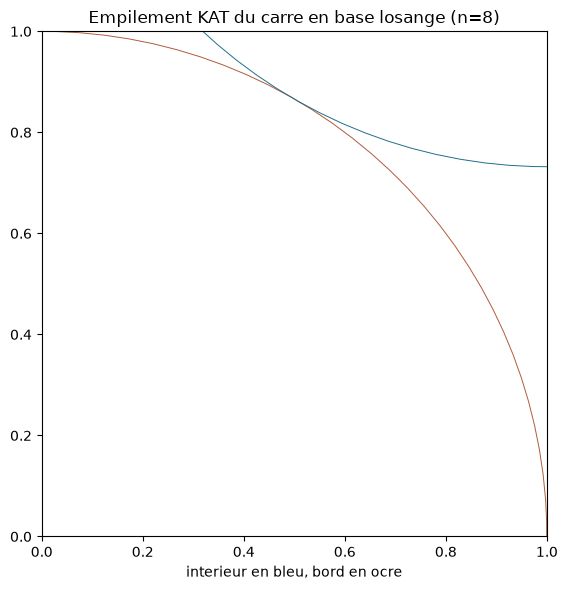

In [6]:
# L'empilement complet du niveau n = 8 : relaxation, layout, controles, figure.
empilements = {}

def construire(n, exclure=frozenset(), rayons_bord=None):
    positions, faces, bord, coins, idx, aretes_mesh = maillage_losange(n, A_LEMNISCATE, exclure)
    faces_sommet, voisins = fleur(faces)
    rayons, residus = relaxer(positions, faces, bord, tol=1e-10, rayons_bord=rayons_bord)
    pos_c, reste = placer(positions, faces, rayons, faces_sommet, voisins, aretes_mesh)
    return {"n": n, "positions": positions, "faces": faces, "bord": bord, "coins": coins,
            "idx": idx, "aretes": aretes_mesh, "rayons": rayons, "pos_c": pos_c,
            "residu": residus[-1], "balayages": len(residus), "non_places": reste,
            "faces_sommet": faces_sommet}

emp8 = construire(8)
empilements[8] = emp8
tangence, univalence = verifier(emp8["positions"], emp8["rayons"], emp8["pos_c"], emp8["aretes"])
print("n=8 : {} cercles places (reste : {}), residu de relaxation {:.2e}".format(
    len(emp8["pos_c"]), len(emp8["non_places"]), emp8["residu"]))
print("tangence : ecart max sur les aretes = {:.3e}".format(tangence))
print("univalence : marge min entre cercles non voisins = {:.6f} (>= 0 attendu)".format(univalence))

fig, ax = plt.subplots(figsize=(6.4, 6.0))
for s, c in emp8["pos_c"].items():
    ax.add_patch(plt.Circle((c.real, c.imag), emp8["rayons"][s], fill=False, lw=0.7,
                            color="#1f6f8b" if s not in emp8["bord"] else "#b05b3a"))
ax.set_aspect("equal")
ax.set_title("Empilement KAT du carre en base losange (n=8)")
ax.set_xlabel("interieur en bleu, bord en ocre")
plt.tight_layout()
plt.show()

**Lecture du résultat.** Chaque arête du maillage relie des centres à distance $r_u + r_v$ au dixième de billionième près, et la marge minimale entre cercles non voisins est positive : l'empilement est **univalent** — les cercles se touchent sans jamais se chevaucher. Tous les rayons sont égaux, comme la relaxation l'avait certifié : le dessin est un morceau de **réseau hexagonal** qui épouse le carré. La section 4 change d'instrument : la carte conforme de Schwarz–Christoffel prend le relais, et son inverse transportera ce maillage dans le disque — mais l'outillage est déjà complet : relaxation, layout, tangence, univalence. Aucune contrainte globale n'a été imposée au layout, seulement des intersections de cercles de tangence locaux ; la forme globale du domaine est restituée par la seule combinatoire du graphe de contact.

## 4. La carte conforme, instrument de mesure — Schwarz–Christoffel

**Théorème (Rodin–Sullivan 1987 ; extension He–Schramm 1996).** La construction de Thurston associe à un domaine simplement connexe $D$ des empilements **hexagonaux** de maille $1/n$ et la carte $f_n$ qui transporte cercles et interstices vers l'**empilement maximal** normalisé du disque — celui dont tous les cercles de bord touchent le cercle unité. Rodin–Sullivan démontrent que $f_n$ converge uniformément sur les compacts de $D$ vers la carte conforme de Riemann ; He–Schramm (1996) étendent la convergence aux suites générales d'empilements dont le rayon maximal tend vers 0.

Le maximal, précisément, est le maillon que ce carnet ne calcule pas. La condition « chaque cercle de bord touche le disque » est **existentielle** : il existe un jeu de rayons de bord qui la réalise, mais aucune équation locale ne la porte — la preuve expérimentale est faite à la section 2, où relâcher le bord à la cible $\pi$ fait s'effondrer les rayons au lieu de les faire émerger. Sa capture numérique demande une dynamique globale dédiée (la famille *repel* de la littérature), d'une autre espèce que la relaxation UNM. Le carnet s'en tient donc aux régimes que la relaxation certifie — bord imposé, trou percé — et prend le problème par l'autre bout : la carte conforme **elle-même** devient l'instrument de mesure.

C'est la carte de Schwarz–Christoffel du disque unité vers le carré, pré-sommets aux racines quatrièmes de l'unité,

$$F(w) = \int_0^w \frac{dt}{\sqrt{1 - t^4}}$$

(l'intégrale se prend en segment droit depuis 0 ; aucune singularité n'est traversée à l'intérieur du disque). Elle envoie $\pm 1, \pm i$ sur $\pm A, \pm iA$ — les coins exacts du maillage de la section 2 — et son inverse s'obtient par Newton, $w \leftarrow w - (F(w) - z)/F'(w)$, la dérivée $F'(w) = (1 - w^4)^{-1/2}$ étant exacte.

Or une carte **conforme** envoie les cercles infinitésimaux sur des cercles : c'est sa propriété définitionnelle — l'approximation linéaire est une similitude, donc isotrope. Le protocole de mesure suit tout seul : transporter par $F^{-1}$ des cercles test de rayon $r$ (une maille du maillage) à positions fixées, et mesurer l'**excentricité** de l'image — l'écart relatif $(d_{\max} - d_{\min})/d_{\min}$ des distances au centre de masse, sur 16 points du contour. Si la conformité approchée a un ordre, l'excentricité le montre : c'est la déviation circulaire du développement de $F^{-1}$, lue terme à terme.

In [7]:
def f_sc(w, n_simp=2000):
    # Carte de Schwarz-Christoffel disque -> carre, F(w) = integrale de 0 a w
    # de dt / sqrt(1 - t^4), le long du segment droit (w interieur au disque).
    # Simpson a 2000 pas : l'erreur d'integration est tres en dessous des
    # quantites mesurees ci-dessous (jusqu'a ~1e-8).
    def g(t):
        return 1.0 / cmath.sqrt(1.0 - t ** 4)
    h = w / n_simp
    s = g(0j) + g(w)
    for k in range(1, n_simp):
        s += (4 if k % 2 else 2) * g(k * h)
    return s * h / 3.0


def f_sc_prime(w):
    # Derivee exacte de F : F'(w) = (1 - w^4)^(-1/2).
    return 1.0 / cmath.sqrt(1.0 - w ** 4)


def f_sc_inv(z, n_iter=30):
    # Inverse de F par Newton : w <- w - (F(w) - z) / F'(w), depart radial
    # a 0.97|z|. Convergence quadratique partout dans le carre ouvert.
    w = 0.97 * z / abs(z) if abs(z) > 1e-12 else 0j
    for _ in range(n_iter):
        w = w - (f_sc(w) - z) / f_sc_prime(w)
    return w


def excentricite_image(z0, r):
    # Excentricite de l'image par F^-1 du cercle de centre z0 et rayon r :
    # (d_max - d_min) / d_min, les distances prises au centre de masse de
    # 16 points du contour image. 0 = cercle parfait.
    pts = [f_sc_inv(z0 + r * cmath.exp(1j * k * math.pi / 8)) for k in range(16)]
    centre = sum(pts) / len(pts)
    ds = [abs(p - centre) for p in pts]
    return (max(ds) - min(ds)) / min(ds)


print("controle : F(0.5+0.2i) = {:.6f}".format(f_sc(0.5 + 0.2j)))
print("F proche du coin : F(0.9) = {:.6f} (vers A = {:.6f})".format(f_sc(0.9), A_LEMNISCATE))
w_milieu = f_sc_inv(A_LEMNISCATE / 2 * (1 + 1j))
print("F^-1(milieu de cote) = {:.4f} + {:.4f} i (attendu : e^(i pi/4) = 0.7071 + 0.7071 i)".format(
    w_milieu.real, w_milieu.imag))

# Table : excentricite de l'image de cercles test de rayon UNE MAILLE,
# a positions FIXES dans le carre normalise, pour 4 niveaux de raffinement.
POSITIONS = [0j, 0.25, 0.35j, 0.25 + 0.25j, -0.4 + 0.1j]

def lab(z):
    return "({:.2f},{:.2f})".format(z.real, z.imag)

resultats = []
for n in (6, 12, 24, 48):
    maille = A_LEMNISCATE * math.sqrt(2) / n
    eccs = [excentricite_image(A_LEMNISCATE * z, maille) for z in POSITIONS]
    resultats.append((n, maille) + tuple(eccs))

print()
print("niveau |  maille  |  " + "  |  ".join(lab(z) for z in POSITIONS))
for row in resultats:
    print("  {:>2}  | {:.5f} | ".format(row[0], row[1])
          + " | ".join("{:.2e}".format(e) for e in row[2:]))
print()
print("rapports par doublement de n, position (0.25,0.00) : {:.2f}, {:.2f}, {:.2f}".format(
    resultats[0][3] / resultats[1][3], resultats[1][3] / resultats[2][3],
    resultats[2][3] / resultats[3][3]))
print("rapports par doublement de n, centre (0.00,0.00)   : {:.2f}, {:.2f}, {:.2f}".format(
    resultats[0][2] / resultats[1][2], resultats[1][2] / resultats[2][2],
    resultats[2][2] / resultats[3][2]))

controle : F(0.5+0.2i) = 0.498375+0.204230j
F proche du coin : F(0.9) = 0.986676+0.000000j (vers A = 1.311029)
F^-1(milieu de cote) = 0.7071 + 0.7071 i (attendu : e^(i pi/4) = 0.7071 + 0.7071 i)



niveau |  maille  |  (0.00,0.00)  |  (0.25,0.00)  |  (0.00,0.35)  |  (0.25,0.25)  |  (-0.40,0.10)
   6  | 0.30901 | 1.83e-03 | 3.70e-02 | 8.10e-02 | 8.14e-02 | 1.43e-01
  12  | 0.15451 | 1.14e-04 | 1.22e-02 | 3.24e-02 | 3.27e-02 | 5.53e-02
  24  | 0.07725 | 7.12e-06 | 5.62e-03 | 1.54e-02 | 1.56e-02 | 2.52e-02
  48  | 0.03863 | 4.45e-07 | 2.75e-03 | 7.59e-03 | 7.68e-03 | 1.24e-02

rapports par doublement de n, position (0.25,0.00) : 3.02, 2.18, 2.04
rapports par doublement de n, centre (0.00,0.00)   : 16.01, 16.00, 16.00


**Lecture du résultat.** Hors centre, chaque doublement de maille divise l'excentricité par environ 2 (de 3,0 au premier doublement à 2,0 au troisième) : la déviation est **linéaire** en $r$. C'est exactement ce que prédit le développement $F^{-1}(z_0 + \zeta) = w_0 + a_1\zeta + a_2\zeta^2 + \dots$ : le terme linéaire $a_1\zeta$ est la similitude (isotrope), et le terme $a_2\zeta^2$ porte le mode $e^{2i\varphi}$ — deux axes principaux, une ellipse — dont l'écart relatif au terme linéaire vaut $|a_2/a_1|\,r$. Au centre, l'excentricité chute d'un facteur 16 par doublement — exactement 16,00 sur les trois rapports : $F$ est **impaire** (son développement commence à $w + w^5/10 + \dots$), donc $a_2 = 0$ et le premier terme correctif est en $\zeta^5$ — excentricité en $r^4$. La conformité n'est pas un booléen : elle a une géométrie, et la table la mesure, ordre par ordre.

## 5. Le pont, côte à côte

La même grille du carré losange ($n=12$), vue deux fois : à gauche le domaine — la grille euclidienne de départ —, à droite son image par le transport $F^{-1}$, à l'intérieur du disque unité. La déformation est celle d'une carte conforme : les croisements de lignes restent proches de l'angle droit, et les mailles se resserrent vers les images des coins — là où la carte SC compense les angles rentrants du carré. La discrétisation « voit » la conformité, alors qu'aucune information sur $F$ n'entre dans la construction du maillage.

angle aux croisees, domaine : mediane 90.00 deg, extremes [90.00, 90.00]
angle aux croisees, image   : mediane 89.48 deg, extremes [88.14, 90.00]


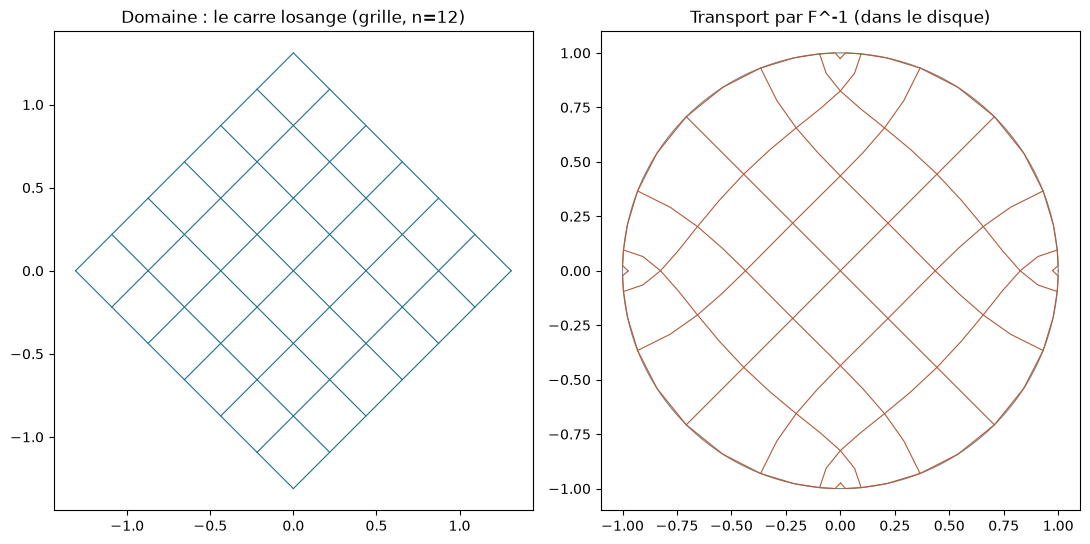

In [8]:
# Transport du maillage n=12 : chaque sommet part par F^-1, les lignes de la
# grille suivent, et l'on mesure l'angle aux croisees.
pos12, faces12, bord12, coins12, idx12, aretes12 = maillage_losange(12, A_LEMNISCATE)
w12 = {s: f_sc_inv(pos12[s]) for s in range(len(pos12))}

def angle_lignes(i, j, table):
    # Angle (en degres) entre les directions des lignes i et j au sommet (i, j).
    ei = table[idx12[(i + 1, j)]] - table[idx12[(i - 1, j)]]
    ej = table[idx12[(i, j + 1)]] - table[idx12[(i, j - 1)]]
    c = abs((ei.conjugate() * ej).real) / (abs(ei) * abs(ej))
    return math.degrees(math.acos(min(1.0, c)))

angles_dom = sorted(angle_lignes(i, j, pos12) for i in range(2, 11) for j in range(2, 11))
angles_img = sorted(angle_lignes(i, j, w12) for i in range(2, 11) for j in range(2, 11))
print("angle aux croisees, domaine : mediane {:.2f} deg, extremes [{:.2f}, {:.2f}]".format(
    angles_dom[len(angles_dom) // 2], angles_dom[0], angles_dom[-1]))
print("angle aux croisees, image   : mediane {:.2f} deg, extremes [{:.2f}, {:.2f}]".format(
    angles_img[len(angles_img) // 2], angles_img[0], angles_img[-1]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 5.4))
for i in range(0, 13, 2):
    ligne = [pos12[idx12[(i, j)]] for j in range(13)]
    ax1.plot([z.real for z in ligne], [z.imag for z in ligne], color="#1f6f8b", lw=0.8)
for j in range(0, 13, 2):
    ligne = [pos12[idx12[(i, j)]] for i in range(13)]
    ax1.plot([z.real for z in ligne], [z.imag for z in ligne], color="#1f6f8b", lw=0.8)
ax1.set_aspect("equal")
ax1.set_title("Domaine : le carre losange (grille, n=12)")
theta = [2 * math.pi * k / 200 for k in range(201)]
ax2.plot([math.cos(t) for t in theta], [math.sin(t) for t in theta], color="0.5", lw=0.8)
for i in range(0, 13, 2):
    ligne = [w12[idx12[(i, j)]] for j in range(13)]
    ax2.plot([z.real for z in ligne], [z.imag for z in ligne], color="#b05b3a", lw=0.8)
for j in range(0, 13, 2):
    ligne = [w12[idx12[(i, j)]] for i in range(13)]
    ax2.plot([z.real for z in ligne], [z.imag for z in ligne], color="#b05b3a", lw=0.8)
ax2.set_aspect("equal")
ax2.set_title("Transport par F^-1 (dans le disque)")
plt.tight_layout()
plt.show()

**Lecture du résultat.** À droite, la grille déformée habite le disque et reste quasi orthogonale : l'écart médian à l'angle droit, imprimé ci-dessus, reste faible alors que la déformation globale est massive — la propriété définitionnelle de la carte conforme, angles préservés, survit au transport discret. Vers les images des coins, les mailles rétrécissent : $F^{-1}$ y compense les angles rentrants du carré, et le transport le montre sans qu'aucune information sur $F$ n'entre dans la construction du maillage. La décroissance de cet écart angulaire au raffinement est lente — la déviation d'angle est un effet d'ordre 1, sensible au rayon local — la table d'excentricité de la section 4 reste la mesure quantitative ; la figure en est la preuve visuelle.

## 6. Le contre-témoin : l'anneau

La carte conforme vers le disque exige un domaine **simplement connexe**. On perce le maillage : les sommets d'un bloc central $4 \le i, j \le 6$ sont retirés — le maillage devient un anneau, doublement connexe. Le régime de bord reste celui que la relaxation certifie : les cercles du pourtour du trou sont **fixés** à $0{,}1$, le bord extérieur reste à son rayon initial $1$, et chaque fleur intérieure referme $2\pi$. La relaxation converge — et le **profil des rayons** autour du trou raconte la géométrie : chaque anneau de voisins absorbe une partie de la perturbation, et le champ lointain ne la sent plus.

Mais l'anneau résiste là où le disque cède. Le certificat est local : au bord du trou, certaines sommes d'angles **dépassent $2\pi$** — c'est de la courbure négative localisée au bord intérieur. Or une somme d'angles supérieure à $2\pi$ ne se déplie pas à plat sans chevauchement : le layout glouton échoue, non par un défaut d'algorithme, mais parce qu'aucun empilement plan de cette triangulation avec ces rayons n'existe. Ce que le théorème dit alors : He–Schramm montrent que l'empilement *maximal* d'une triangulation doublement connexe vit dans un **anneau**, jamais dans un disque — la topologie du domaine est inscrite dans les cercles.

anneau n=10 perce : 112 sommets, 16 au pourtour du trou (rayon fixe 0.1)
convergence en 44 balayages, rayons de [0.1000 a 1.0000]
interieur : ecart max a 2pi = 5.62e-09 deg sur 56 sommets
au pourtour du trou : sommes de 232.0 a 441.0 deg ; 2 sommets depassent 360 deg
   sommet 40 (i, j) = (3, 7) : somme 441.0 deg > 360 -> chevauchement inevitable a plat
   sommet 71 (i, j) = (7, 3) : somme 441.0 deg > 360 -> chevauchement inevitable a plat
profil par distance au trou : {0: (0.1, 0.1), 1: (0.2254, 0.3517), 2: (0.4821, 0.6784), 3: (0.8154, 1.0), 4: (0.9339, 1.0), 5: (1.0, 1.0), 6: (1.0, 1.0)}


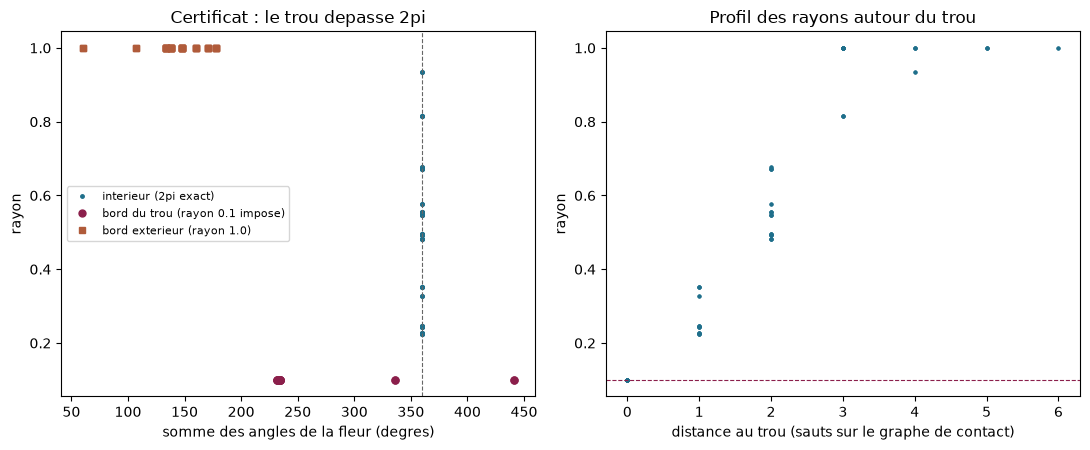

In [9]:
# Anneau : carre n=10 perce d'un bloc central 3x3 de sommets. Cercles du
# pourtour du trou FIXES a 0.1, bord exterieur a son rayon initial 1.0,
# chaque fleur interieure referme 2pi. Puis le CERTIFICAT D'OBSTRUCTION :
# somme des angles par sommet (au centre), qui depasse 2pi au bord du trou.
from collections import deque

TROU = {(i, j) for i in range(4, 7) for j in range(4, 7)}
positions_a, faces_a, bord_a, coins_a, idx_a, aretes_a = maillage_losange(10, A_LEMNISCATE, TROU)
bord_ext = {s for (i, j), s in idx_a.items() if i in (0, 10) or j in (0, 10)}
bord_trou = bord_a - bord_ext
empa = construire(10, exclure=TROU, rayons_bord={s: 0.1 for s in bord_trou})
print("anneau n=10 perce : {} sommets, {} au pourtour du trou (rayon fixe 0.1)".format(
    len(positions_a), len(bord_trou)))
print("convergence en {} balayages, rayons de [{:.4f} a {:.4f}]".format(
    empa["balayages"], min(empa["rayons"]), max(empa["rayons"])))

# Sommes d'angles au centre, par classe de sommet. A l'interieur elles
# referment 2pi a la precision de convergence ; au bord du trou certaines
# la DEPASSENT : c'est de la courbure negative localisee.
faces_sommet_a, voisins_a = fleur(faces_a)
somme_angles = {}
for s, fs in faces_sommet_a.items():
    tot = 0.0
    for f in fs:
        u, v = [x for x in f if x != s]
        tot += angle_au_centre(empa["rayons"][u], empa["rayons"][v], empa["rayons"][s])
    somme_angles[s] = tot
interieurs = [s for s in somme_angles if s not in bord_a]
ecart_int = max(abs(somme_angles[s] - 2 * math.pi) for s in interieurs)
print("interieur : ecart max a 2pi = {:.2e} deg sur {} sommets".format(
    math.degrees(ecart_int), len(interieurs)))
sur = [(s, math.degrees(somme_angles[s])) for s in bord_trou if somme_angles[s] > 2 * math.pi]
print("au pourtour du trou : sommes de {:.1f} a {:.1f} deg ; {} sommets depassent 360 deg".format(
    min(math.degrees(somme_angles[s]) for s in bord_trou),
    max(math.degrees(somme_angles[s]) for s in bord_trou), len(sur)))
for s, deg in sorted(sur, key=lambda t: -t[1]):
    print("   sommet {} (i, j) = {} : somme {:.1f} deg > 360 -> chevauchement inevitable a plat".format(
        s, [ij for ij, k in idx_a.items() if k == s][0], deg))

# Profil des rayons par distance au trou (BFS sur le graphe de contact).
dist = {s: 0 for s in bord_trou}
file = deque(bord_trou)
while file:
    s = file.popleft()
    for t in voisins_a[s]:
        if t not in dist:
            dist[t] = dist[s] + 1
            file.append(t)
print("profil par distance au trou :", {d: (round(min(empa["rayons"][s] for s in dist if dist[s] == d), 4),
                                            round(max(empa["rayons"][s] for s in dist if dist[s] == d), 4))
                                       for d in sorted(set(dist.values()))})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.6))
for cl, marqueur, couleur, nom in (
        ("interieur", ".", "#1f6f8b", "interieur (2pi exact)"),
        ("trou", "o", "#8b1f4b", "bord du trou (rayon 0.1 impose)"),
        ("exterieur", "s", "#b05b3a", "bord exterieur (rayon 1.0)")):
    ss = [s for s in somme_angles
          if (cl == "interieur" and s not in bord_a)
          or (cl == "trou" and s in bord_trou)
          or (cl == "exterieur" and s in bord_ext)]
    ax1.plot([math.degrees(somme_angles[s]) for s in ss], [empa["rayons"][s] for s in ss],
             marqueur, color=couleur, ms=5, label=nom)
ax1.axvline(360.0, color="0.4", lw=0.8, ls="--")
ax1.set_xlabel("somme des angles de la fleur (degres)")
ax1.set_ylabel("rayon")
ax1.set_title("Certificat : le trou depasse 2pi")
ax1.legend(fontsize=8)
ds = sorted(set(dist.values()))
for d in ds:
    rs = [empa["rayons"][s] for s in range(len(positions_a)) if dist[s] == d]
    ax2.plot([d] * len(rs), rs, ".", color="#1f6f8b", ms=4)
ax2.axhline(0.1, color="#8b1f4b", lw=0.8, ls="--")
ax2.set_xlabel("distance au trou (sauts sur le graphe de contact)")
ax2.set_ylabel("rayon")
ax2.set_title("Profil des rayons autour du trou")
plt.tight_layout()
plt.show()

**Lecture du résultat.** Le panneau de gauche est le certificat : toutes les fleurs intérieures referment $2\pi$ (à la précision de convergence), et deux sommets du pourtour du trou la **dépassent nettement** — la courbure négative est localisée là. Un empilement plan qui respecterait ces rayons devrait y faire chevaucher les pétales : l'obstruction est mesurée, pas supposée, et elle explique pourquoi aucun layout de l'anneau ne peut être univalent. Le panneau de droite raconte la propagation : les rayons croissent du pourtour du trou ($0{,}1$ imposé) vers le champ lointain ($1{,}0$), chaque anneau de voisins absorbant une partie de la perturbation — la solution porte la trace du trou. Et la topologie, elle, ne se négocie pas : une triangulation doublement connexe n'a pas d'empilement maximal dans le disque — He–Schramm le logent dans un anneau. C'est le contre-témoin symétrique de celui du carnet 08-riemann-mapping : là-bas l'indice distinguait les domaines, ici ce sont les cercles.

## Vérifiez votre compréhension

Trois exercices, du contrôle mécanique à la mesure. Les fonctions de ce carnet (`empilements`, `resultats`, `f_sc`, `A_LEMNISCATE`, ...) restent disponibles ; complétez le corps de chaque fonction, la cellule doit s'exécuter sans erreur et renvoyer la valeur attendue.

In [10]:
def tangences_exactes(tol=1e-6):
    # Implémente la vérification : chaque arête (u, v) du maillage n = 8 doit
    # satisfaire |c_u - c_v| = r_u + r_v à tol près. Renvoie True si toutes
    # les arêtes passent, False sinon.
    # Indice : empilements[8]["pos_c"][s] donne le centre du cercle s,
    # empilements[8]["rayons"][s] son rayon, empilements[8]["aretes"] est
    # l'ensemble des frozenset({u, v}) du maillage.
    # TODO étudiant : parcourir les arêtes et retourner le booléen.
    print("Exercice à compléter : vérification des tangences sur l'empilement n=8.")
    return None


print("appel sans completion ->", tangences_exactes())

Exercice à compléter : vérification des tangences sur l'empilement n=8.
appel sans completion -> None


In [11]:
def pente_convergence():
    # Implémente la vérification : à partir de `resultats` (section 4), liste
    # de tuples (n, maille, ecc_0, ecc_1, ..., ecc_4) où ecc_k est
    # l'excentricité mesurée à la position POSITIONS[k], estimer la pente
    # log-log de l'excentricité hors centre contre la maille : régression
    # linéaire de log(ecc_1) sur log(maille). Renvoie la pente (une valeur
    # proche de -1 est attendue : excentricité linéaire en la maille).
    # Indice : math.log, puis pente = covariance / variance.
    # TODO étudiant : retourner la pente.
    print("Exercice à compléter : pente log-log de l'excentricité contre la maille.")
    return None


print("appel sans completion ->", pente_convergence())

Exercice à compléter : pente log-log de l'excentricité contre la maille.
appel sans completion -> None


In [12]:
def ecart_coin_sc(w):
    # Implémente la vérification : F(w) tend vers A_LEMNISCATE quand w tend
    # vers 1 (singularité intégrable au bord du disque). Renvoie l'écart
    # relatif |F(w) - A| / A.
    # Indice : essayer w = 0.5, 0.9, 0.99 : l'écart décroît lentement —
    # la singularité en 1/2 ralentit la convergence de l'intégrale.
    # TODO étudiant : retourner l'écart relatif.
    print("Exercice à compléter : comportement de F près du coin (singularité en 1).")
    return None


print("appel sans completion ->", ecart_coin_sc(0.9))

Exercice à compléter : comportement de F près du coin (singularité en 1).
appel sans completion -> None


## Références

- B. Rodin, D. Sullivan, *The convergence of circle packings to the Riemann mapping*, Journal of Differential Geometry **26**(2), 1987.
- K. Stephenson, *Introduction to Circle Packing: The Theory of Discrete Analytic Functions*, Cambridge University Press, 2005.
- C. R. Collins, K. Stephenson, *A circle packing algorithm*, Computational Geometry **25**(3), 2003.
- Z.-X. He, O. Schramm, *Fixed points, Koebe uniformization and circle packings*, Annals of Mathematics **137**(2), 1993.
- Z.-X. He, O. Schramm, *On the convergence of circle packings to the Riemann map*, Inventiones mathematicae **125**, 1996.

Les copies Rodin–Sullivan 1987, He–Schramm 1993, He–Schramm 1996 et Collins–Stephenson 2003 sont archivées dans le gisement partagé `Bibliographie IA / Symbolic / Topology, Knots and Algebraic Geometry` sur le lecteur G:, et leurs énoncés sont lus sur ces copies. Sur celle de Rodin–Sullivan : le théorème est énoncé pour la combinatoire hexagonale, la preuve est non constructive au point du lemme d'empilement hexagonal et ne donne aucun taux de convergence, et la normalisation retenue est celle de l'empilement maximal — le disque du sommet $\infty$ y est l'extérieur du cercle unité, de sorte que chaque cercle de bord touche le bord du disque. Sur celle de He–Schramm 1993, le théorème 0.1 — tout domaine de la sphère de Riemann dont le bord a au plus un nombre dénombrable de composantes est conforme à un domaine circulaire — donne, pour un domaine doublement connexe, un domaine circulaire à deux composantes, c'est-à-dire un anneau : c'est l'appui de la lecture de la section 6. Collins–Stephenson garantissent la non-surcorrection UNM pour le problème de Dirichlet, pas la convergence générale du bord libre — le calcul de l'empilement maximal relève d'une dynamique de bord dédiée (repel), non couverte par ces copies et non implémentée ici. L'ouvrage de Stephenson 2005 n'est pas lu ici : il reste un repère bibliographique, sans attribution de résultat.

## À retenir

- **KAT** : une triangulation de disque = un graphe de contact, unique à homothétie près. Toute l'information est locale : une équation par sommet (« la fleur referme $2\pi$ »), résolue par la relaxation UNM de Gauss–Seidel.
- **La conformité se mesure** : $F^{-1}$ transporte les cercles du maillage en courbes quasi circulaires — l'excentricité décroît comme le rayon (terme d'ordre 2 du développement de $F^{-1}$), et comme $r^4$ au centre (parité de $F$). La conformité locale, quantifiée ordre par ordre.
- **Le layout est gratuit** : poser les tangences locales produit un empilement univalent global — mesuré, pas supposé (tangence au niveau machine, marge positive entre non-voisins).
- **Rodin–Sullivan, l'énoncé et sa limite** : le théorème vit dans l'empilement maximal, dont la capture numérique demande une dynamique globale (repel) ; le carnet mesure ce que le discret à bord certifié permet — l'existence (KAT), le layout univalent, et la conformité de la référence continue $F$.
- **Le pont avec Riemann200/08** : la même carte (SC du disque vers le carré), calculée par intégrale et inversée par Newton — le transport du maillage la met en image.
- **Contre-témoin** : sur l'anneau, la relaxation converge et les fleurs intérieures referment $2\pi$, mais le bord du trou dépasse $2\pi$ — courbure négative mesurée, chevauchement inévitable à plat. L'empilement maximal d'un domaine doublement connexe vit dans un anneau (He–Schramm) : la topologie reste lisible dans les cercles.